# Comparing Text Representation Methods for Phishing Email Detection

This notebook contains the experiments for my IMT4210 term paper. I compare three text representations using Logistic Regression and examine both classification performance and errors.

## 1. Setup and dataset loading

First, I import the libraries and load the email dataset.

In [4]:
import hashlib
import platform
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

print("Python:", platform.python_version())
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("scikit-learn:", sklearn.__version__)

Python: 3.13.18
pandas: 2.2.3
NumPy: 2.4.6
scikit-learn: 1.6.1


In [5]:
# uploading the file (if phishing_email.csv is already present, no upload is needed)
df = pd.read_csv("phishing_email.csv")

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["label"].value_counts(dropna=False))

Dataset shape: (82486, 2)

Class distribution:
label
1    42891
0    39595
Name: count, dtype: int64


## 2. Initial dataset inspection
First, I check the dataset for missing values, duplicate emails and the distribution of labels. This gives an overview of the data before cleaning.

In [6]:
print("Columns:", df.columns.tolist())
print("\nMissing values:")
print(df[["text_combined", "label"]].isna().sum())
print("\nClass distribution (including missing):")
print(df["label"].value_counts(dropna=False))
print("\nDuplicate email texts:", df.duplicated(subset=["text_combined"]).sum())
print("Conflicting labels for identical nonmissing texts:",
      df.dropna(subset=["text_combined", "label"])
        .groupby("text_combined")["label"].nunique().gt(1).sum())
display(df[["text_combined", "label"]].head(3).assign(
    text_combined=lambda x: x["text_combined"].str.slice(0, 160)))

Columns: ['text_combined', 'label']

Missing values:
text_combined    0
label            0
dtype: int64

Class distribution (including missing):
label
1    42891
0    39595
Name: count, dtype: int64

Duplicate email texts: 408
Conflicting labels for identical nonmissing texts: 0


,text_combined,label
0,hpl nom may 25 2001 see attached file hplno 52...,0
1,nom actual vols 24 th forwarded sabrae zajac h...,0
2,enron actuals march 30 april 1 201 estimated a...,0


## 3. Cleaning
I remove emails with missing text or labels, as well as exact duplicates. I leave the remaining text unchanged and let the vectorizers handle tokenization and lowercasing.

In [7]:
df_clean = (
    df.dropna(subset=["text_combined", "label"])
      .drop_duplicates(subset=["text_combined"], keep="first")
      .copy()
)
df_clean["label"] = df_clean["label"].astype(int)
df_clean = df_clean.reset_index(drop=True)
df_clean["word_count"] = df_clean["text_combined"].str.split().str.len()

assert set(df_clean["label"].unique()) == {0, 1}, "Expected binary labels 0 and 1"
assert df_clean["text_combined"].notna().all()
assert not df_clean["text_combined"].duplicated().any()
print("Raw rows:", len(df))
print("Clean rows:", len(df_clean))
print("Removed rows:", len(df) - len(df_clean))
print("\nCleaned class distribution:")
print(df_clean["label"].value_counts().sort_index())
print("\nWord-count summary:")
print(df_clean["word_count"].describe())
print("Emails with fewer than five words:", (df_clean["word_count"] < 5).sum())

Raw rows: 82486
Clean rows: 82078
Removed rows: 408

Cleaned class distribution:
label
0    39233
1    42845
Name: count, dtype: int64

Word-count summary:
count     82078.000000
mean        160.715003
std         544.992481
min           0.000000
25%          39.000000
50%          78.000000
75%         183.000000
max      107710.000000
Name: word_count, dtype: float64
Emails with fewer than five words: 108


## 4. Stratified train/test split
The cleaned dataset is split into 80% training data and 20% test data. I use a stratified split to keep approximately the same class distribution in both sets. All three models use the same split!

In [8]:
X = df_clean["text_combined"]
y = df_clean["label"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
assert len(X_train) + len(X_test) == len(df_clean)
assert set(X_train).isdisjoint(set(X_test)), "Exact text overlap between splits"
print("Training samples:", len(X_train))
print("Test samples:", len(X_test))
print("\nTraining labels:\n", y_train.value_counts().sort_index())
print("\nTest labels:\n", y_test.value_counts().sort_index())

Training samples: 65662
Test samples: 16416

Training labels:
 label
0    31386
1    34276
Name: count, dtype: int64

Test labels:
 label
0    7847
1    8569
Name: count, dtype: int64


## 5. Model definitions and training
I trained three Logistic Regression models using different text representations: BoW, TF-IDF and TF-IDF with bigrams. The classifier settings are kept the same so I can compare the effect of changing the text representation.

In [9]:
models = {
    "BoW": Pipeline([
        ("vectorizer", CountVectorizer(ngram_range=(1, 1))),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    "TF-IDF": Pipeline([
        ("vectorizer", TfidfVectorizer(ngram_range=(1, 1))),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
    "TF-IDF + n-grams": Pipeline([
        ("vectorizer", TfidfVectorizer(ngram_range=(1, 2))),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42)),
    ]),
}

predictions = {}
rows = []
for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    predictions[name] = pred
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    rows.append({
        "Method": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "False positives": int(fp),
        "False negatives": int(fn),
        "Features": len(model.named_steps["vectorizer"].get_feature_names_out()),
    })

results_df = pd.DataFrame(rows).set_index("Method")
display(results_df.round(4))

Training BoW...
Training TF-IDF...
Training TF-IDF + n-grams...


,Accuracy,Precision,Recall,F1-score,False positives,False negatives,Features
Method,,,,,,,
BoW,0.9876,0.9837,0.9926,0.9882,141,63,552857
TF-IDF,0.9848,0.9815,0.9896,0.9855,160,89,552857
TF-IDF + n-grams,0.9840,0.9831,0.9862,0.9847,145,118,4214669


## 6. Classification results
Here I look at the classification report and confusion matrix for each model. This shows how well they classify each class and how many false positives and false negatives they produce

In [10]:
for name, pred in predictions.items():
    print(f"\n{name}")
    print(classification_report(y_test, pred, labels=[0, 1], digits=4, zero_division=0))
    print("Confusion matrix (actual rows, predicted columns):")
    print(confusion_matrix(y_test, pred, labels=[0, 1]))


BoW
              precision    recall  f1-score   support

           0     0.9919    0.9820    0.9869      7847
           1     0.9837    0.9926    0.9882      8569

    accuracy                         0.9876     16416
   macro avg     0.9878    0.9873    0.9875     16416
weighted avg     0.9876    0.9876    0.9876     16416

Confusion matrix (actual rows, predicted columns):
[[7706  141]
 [  63 8506]]

TF-IDF
              precision    recall  f1-score   support

           0     0.9886    0.9796    0.9841      7847
           1     0.9815    0.9896    0.9855      8569

    accuracy                         0.9848     16416
   macro avg     0.9850    0.9846    0.9848     16416
weighted avg     0.9849    0.9848    0.9848     16416

Confusion matrix (actual rows, predicted columns):
[[7687  160]
 [  89 8480]]

TF-IDF + n-grams
              precision    recall  f1-score   support

           0     0.9849    0.9815    0.9832      7847
           1     0.9831    0.9862    0.9847      8

## 7. Comparing classification errors
I compare the predictions to see how many emails are misclassified by one, two or all three models. I also look at a few examples of emails that all three models got wrong.

In [11]:
error_analysis = pd.DataFrame({
    "text": X_test.to_numpy(),
    "actual": y_test.to_numpy(),
    **predictions,
})
method_names = list(models)
for name in method_names:
    error_analysis[f"{name}_error"] = error_analysis["actual"] != error_analysis[name]
error_columns = [f"{name}_error" for name in method_names]
error_analysis["error_count"] = error_analysis[error_columns].sum(axis=1)
error_analysis["word_count"] = error_analysis["text"].str.split().str.len()

print("Number of models misclassifying an email:")
print(error_analysis["error_count"].value_counts().sort_index())
shared_errors = error_analysis.loc[error_analysis["error_count"] == 3].copy()
print("\nShared false positives:", (shared_errors["actual"] == 0).sum())
print("Shared false negatives:", (shared_errors["actual"] == 1).sum())

preview = shared_errors[["text", "actual", "word_count"]].head(10).copy()
preview["text"] = preview["text"].str.slice(0, 140) + "..."
display(preview)

Number of models misclassifying an email:
error_count
0    16075
1      106
2       95
3      140
Name: count, dtype: int64

Shared false positives: 93
Shared false negatives: 47


,text,actual,word_count
40,joseph brennan vupzesmcolumbiaedu worked well ...,0,30
75,diveintomark rssfeedsspamassassintaintorg url ...,0,41
103,posses whatever drag want winsome neew improov...,1,225
136,iso2022jpbgyrcmetfbcehp04bkei hitoopentextcom ...,0,2695
379,vlad mazek cvladvillecom one pattern match ema...,0,31
509,e mail antonioadventura groups msn com deliver...,1,55
574,aio shin qysavczgmailcom hi group possible att...,0,23
581,human resources industrial relation occupation...,1,36
757,massimiliano marini vualinuxtimeit hint might ...,0,28
847,trade xfnbqbtrademeconz security note trade ne...,0,93


## 8. Error by email length
To see whether the models struggle more with certain message lengths, I group the test emails by word count and calculate the error rate for each group.

In [12]:
bins = [0, 25, 50, 100, 250, 500, np.inf]
length_labels = ["1-25", "26-50", "51-100", "101-250", "251-500", "501+"]
error_analysis["length_group"] = pd.cut(
    error_analysis["word_count"], bins=bins, labels=length_labels, include_lowest=True
)
length_rows = []
for name in method_names:
    summary = error_analysis.groupby("length_group", observed=True)[f"{name}_error"].agg(
        emails="count", errors="sum", error_rate="mean"
    )
    for group, r in summary.iterrows():
        length_rows.append({"Method": name, "Length group": group,
                            "Emails": int(r["emails"]), "Errors": int(r["errors"]),
                            "Error rate (%)": round(100 * r["error_rate"], 2)})
length_results_df = pd.DataFrame(length_rows)
display(length_results_df)

,Method,Length group,Emails,Errors,Error rate (%)
0,BoW,1-25,1995,58,2.91
1,BoW,26-50,3746,39,1.04
2,BoW,51-100,3705,25,0.67
3,BoW,101-250,4604,52,1.13
4,BoW,251-500,1604,17,1.06
5,BoW,501+,762,13,1.71
6,TF-IDF,1-25,1995,59,2.96
7,TF-IDF,26-50,3746,48,1.28
8,TF-IDF,51-100,3705,39,1.05
9,TF-IDF,101-250,4604,63,1.37


## 9. Errors by length and class
The proportion of legitimate and spam/phishing emails may differ between length groups. So I looked at the class distribution and calculate separate error rates for each class.

In [13]:
class_composition = pd.crosstab(
    error_analysis["length_group"], error_analysis["actual"], normalize="index"
).mul(100)
print("Class distribution (%) within length groups:")
display(class_composition.round(2))

class_length_rows = []
for name in method_names:
    summary = (error_analysis.groupby(["length_group", "actual"], observed=True)[f"{name}_error"]
               .agg(emails="count", errors="sum", error_rate="mean").reset_index())
    for _, r in summary.iterrows():
        class_length_rows.append({
            "Method": name, "Length group": r["length_group"], "Actual class": int(r["actual"]),
            "Emails": int(r["emails"]), "Errors": int(r["errors"]),
            "Error rate (%)": round(100 * r["error_rate"], 2),
        })
class_length_results_df = pd.DataFrame(class_length_rows)
display(class_length_results_df)

Class distribution (%) within length groups:


actual,0,1
length_group,,
1-25,28.02,71.98
26-50,30.81,69.19
51-100,54.66,45.34
101-250,56.97,43.03
251-500,58.29,41.71
501+,72.31,27.69


,Method,Length group,Actual class,Emails,Errors,Error rate (%)
0,BoW,1-25,0,559,48,8.59
1,BoW,1-25,1,1436,10,0.70
2,BoW,26-50,0,1154,28,2.43
3,BoW,26-50,1,2592,11,0.42
4,BoW,51-100,0,2025,14,0.69
5,BoW,51-100,1,1680,11,0.65
6,BoW,101-250,0,2623,30,1.14
7,BoW,101-250,1,1981,22,1.11
8,BoW,251-500,0,935,10,1.07
9,BoW,251-500,1,669,7,1.05


## 10. Error rates by email length
This plot compares the error rates across the different email length groups for all three models (specifically to be used in the final pdf report)

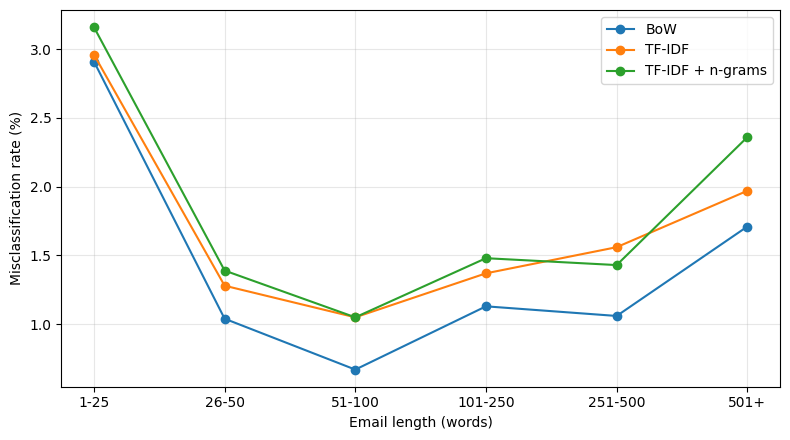

In [14]:
import matplotlib.pyplot as plt

plot_data = length_results_df.pivot(
    index="Length group",
    columns="Method",
    values="Error rate (%)"
)

plot_data = plot_data.reindex(length_labels)

#plot the error rates for each model
plt.figure(figsize=(8, 4.5))

for method in method_names:
    plt.plot(
        plot_data.index,
        plot_data[method],
        marker="o",
        label=method
    )

plt.xlabel("Email length (words)")
plt.ylabel("Misclassification rate (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("error_rates_by_length.pdf", bbox_inches="tight")
plt.show()
